## Movie Recommendation with Collaborative Filtering

In this exercise, we’ll use the **MovieLens movie rating dataset** to build a recommendation system. You’ll start with a linear regression model and then explore collaborative filtering techniques, comparing their performance and combining them into an ensemble model for improved recommendations.

MovieLens DataSet is one of the most commonly used datasets for building and evaluating recommender systems. For this exercise, we'll use a light version.

In [ ]:
# restart the session after running this code
!pip install "numpy<2.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 69.7 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pytensor 2.35.1 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
opencv-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
shap 0.50.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
opencv-python-headless 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
jaxlib 0.7.2 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
jax 0.7.2 re

In [ ]:
# install surprise library

# Type this command in terminal / anaconda prompt
#conda install -c conda-forge scikit-surprise

# Install scikit-surprise library
!pip install scikit-surprise

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.4/154.4 kB 2.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-surprise: filename=scikit_surprise-1.1.4-cp312-cp312-linux_x86_64.whl size=2555152 sha256=c097949146deb23d243f85a3d34331138d88997a6b9cac520bf3911d5525e125
  Stored in directory: /root/.cache/pip/wheels/75/fa/bc/739bc2cb1fbaab6061854e6cfbb81a0ae52c92a502a7fa454b
Successfully built scikit-surprise


## Restart the session before moving on.

In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os
warnings.filterwarnings('ignore')

from sklearn import linear_model
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

# import functions from surprise
from surprise import KNNBasic
from surprise import Dataset
from surprise import accuracy
from surprise import BaselineOnly, Dataset, Reader
from surprise.model_selection import train_test_split as surprise_train_test_split
from surprise.model_selection import cross_validate


from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import cross_val_predict
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, roc_auc_score, f1_score, roc_curve, auc
from sklearn.metrics import mean_absolute_error


## Part 1: Import Dataset and Explore the Data


In [ ]:
# Import the provided movies ratings dataset
df = pd.read_csv('data/movies_ratings_100k.csv')


In [ ]:
# Explore the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   user_id   100000 non-null  int64 
 1   movie_id  100000 non-null  int64 
 2   ratings   100000 non-null  int64 
 3   title     98883 non-null   object
 4   genres    98883 non-null   object
 5   gender    100000 non-null  object
 6   zipcode   100000 non-null  object
 7   age_desc  100000 non-null  object
 8   occ_desc  100000 non-null  object
dtypes: int64(3), object(6)
memory usage: 6.9+ MB


In [ ]:
df.describe()

,user_id,movie_id,ratings
count,100000.000000,100000.000000,100000.000000
mean,362.877840,431.545050,3.529860
std,249.779236,336.405024,1.125674
min,0.000000,0.000000,1.000000
25%,147.000000,164.000000,3.000000
50%,325.000000,350.500000,4.000000
75%,540.000000,633.000000,4.000000
max,943.000000,1679.000000,5.000000


**Question 1:** Perform an initial analysis to uncover key insights from the dataset and prepare for subsequent modelling tasks. Specifically, report by answering the following questions:

#### User-related
* How many unique users are in the dataset?
* What is the user age distribution?

In [ ]:
len(df['user_id'].unique())

944

In [ ]:
df.sort_values(by='user_id')

,user_id,movie_id,ratings,title,genres,gender,zipcode,age_desc,occ_desc
0,0,0,3,Toy Story (1995),Animation|Children's|Comedy,F,48067,Under 18,K-12 student
70063,0,869,3,Gone Fishin' (1997),Comedy,F,48067,Under 18,K-12 student
70138,0,872,4,Shadow of Angels (Schatten der Engel) (1976),Drama,F,48067,Under 18,K-12 student
16222,0,119,4,Race the Sun (1996),Drama,F,48067,Under 18,K-12 student
15943,0,114,4,Happiness Is in the Field (1995),Comedy,F,48067,Under 18,K-12 student
...,...,...,...,...,...,...,...,...,...
88949,943,720,1,Halfmoon (Paul Bowles - Halbmond) (1995),Drama,M,91505,35-44,other or not specified
93620,943,168,2,Free Willy 2: The Adventure Home (1995),Adventure|Children's|Drama,M,91505,35-44,other or not specified
90145,943,73,3,Bed of Roses (1996),Drama|Romance,M,91505,35-44,other or not specified
81127,943,443,2,Even Cowgirls Get the Blues (1993),Comedy|Romance,M,91505,35-44,other or not specified


In [ ]:
agedf=df[['user_id','age_desc']].drop_duplicates()
clean_agedf=agedf.set_index('user_id').sort_index()
clean_agedf.groupby('age_desc').size()

,0
age_desc,
18-24,208
25-34,306
35-44,190
45-49,78
50-55,69
56+,58
Under 18,35


#### Movie-related
* How many unique movies are included?
* Which movie has the highest number of ratings, and how many ratings does it have?


In [ ]:
print(len(df['movie_id'].unique()))
print(len(df['title'].unique()))

1663
1619


In [ ]:
rating1df=df[['movie_id','ratings','title']].drop_duplicates()
highest_rated_movie_id=rating1df.groupby(['movie_id','title']).size()
highest_rated_movie_id.sort_values(ascending=False)

,,0
movie_id,title,
0,Toy Story (1995),5
709,Celtic Pride (1996),5
712,Of Love and Shadows (1994),5
713,Dead Man (1995),5
714,"Horseman on the Roof, The (Hussard sur le toit, Le) (1995)",5
...,...,...
1531,Sprung (1997),1
1528,Nowhere (1997),1
1523,"Turning, The (1992)",1


#### Rating-related
* How many total ratings are recorded?
* How is the rating distribution?
* Which user has rated the most movies, and how many ratings have they given?
* How many missing values exist, and in which columns?

In [ ]:
ratingdf=df[['user_id','movie_id','ratings']].dropna()
len(ratingdf)

100000

In [ ]:
rating2df=df[['movie_id','ratings','title']].drop_duplicates()
rating2df.groupby(['movie_id','title']).size()

,,0
movie_id,title,
0,Toy Story (1995),5
1,Jumanji (1995),5
2,Grumpier Old Men (1995),5
3,Waiting to Exhale (1995),5
4,Father of the Bride Part II (1995),5
...,...,...
1664,Bean (1997),2
1668,"Tango Lesson, The (1997)",1
1674,Incognito (1997),1


In [ ]:
rating3df=df[['user_id','ratings']]
rating3df.groupby('user_id').size().sort_values(ascending=False).head(10)

,0
user_id,
66,591
112,556
5,523
13,464
325,446
345,440
304,439
65,417
214,413


In [ ]:
rating4df=df[df.isnull().any(axis=1)]
rating4df

,user_id,movie_id,ratings,title,genres,gender,zipcode,age_desc,occ_desc
12671,345,90,5,NaN,NaN,F,55110,25-34,other or not specified
12672,65,90,5,NaN,NaN,M,57706,25-34,tradesman/craftsman
12673,303,90,5,NaN,NaN,M,55414,25-34,other or not specified
12674,94,90,4,NaN,NaN,M,98201,45-49,other or not specified
12675,868,90,4,NaN,NaN,M,92026,18-24,writer
...,...,...,...,...,...,...,...,...,...
99657,303,1228,2,NaN,NaN,M,55414,25-34,other or not specified
99713,267,685,3,NaN,NaN,F,29708,18-24,programmer
99787,7,676,3,NaN,NaN,M,11413,25-34,programmer
99859,916,685,2,NaN,NaN,M,92117,50-55,doctor/health care


## Part 2: Data Preprocessing

In [ ]:
def encoding_categorical(df_tmp):

  movie_means = df_tmp.groupby('movie_id')['ratings'].mean() # Target encoding movie_id with ratings
  df_tmp['movie_ratings'] = df_tmp['movie_id'].map(movie_means)

  user_means = df_tmp.groupby('user_id')['ratings'].mean() # Target encoding user_id with ratings
  df_tmp['user_ratings'] = df_tmp['user_id'].map(user_means)

  age_column = ['Under 18', '18-24', '25-34', '35-44', '45-49', '50-55', '56+'] #Ordinal encoding for ages
  df_tmp['age_order'] = df_tmp['age_desc'].map({age: i for i, age in enumerate(age_column)})

  df_tmp = pd.get_dummies(df_tmp, columns=['gender'], drop_first=True) # One-hot encoding for gender and occupation

  le = LabelEncoder()
  df_tmp['occ_encoded'] = le.fit_transform(df_tmp['occ_desc'])

  # One-hot encoding for genre
  genre_list_unique = set() # Make unique list of genre
  genre_array_row = []

  for i in range(len(df_tmp)):
    s = df_tmp['genres'].iloc[int(i)]
    genre_array = s.split('|')
    genre_array_row.append(genre_array)
    for j in genre_array:
      genre_list_unique.add(j)

  for i in genre_list_unique: # Set a new genre column
    new_genre_column = "genre_" + i
    df_tmp[new_genre_column] = 0 #set initial to zero


  for index_array, index_dataframe in zip(range(len(genre_array_row)), df_tmp.index): # Update genre columns based on genre_array_row
      for genre in genre_array_row[index_array]:
        # print(genre, index_dataframe)
        df_tmp[f'genre_{genre}'].loc[index_dataframe] = 1

  df_tmp = df_tmp.drop(['genres', 'zipcode', 'user_id', 'movie_id', 'title', 'age_desc', 'occ_desc'], axis=1) #remove the raw columns

  df_tmp = df_tmp.replace({True:1, False:0})
  df_tmp = df_tmp.replace({'Yes':1, 'No':0})

  return df_tmp

In [ ]:
# Write your code below to precess necessary steps
# make a copy of your data
df_copy = df.copy()
print(f"The number of rows BEFORE missing value removed: {len(df_copy)}")

# Handle missing values
df_copy = df_copy.dropna() # Drop value with missing title and genre
print(f"The number of rows AFTER missing value removed: {len(df_copy)}\n\n")
# df_copy.count()

# Encode categorical features
df_copy = encoding_categorical(df_copy)

# Create features and target list
features = df_copy.columns.drop('ratings').tolist()
target = ['ratings']
x = df_copy[features]
y = df_copy[target]

# Data splitting by 80/20
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state=100)

# Standard Scaling
zscore_scaler = preprocessing.StandardScaler().fit(x_train) #Z scaler
x_train_scaled = pd.DataFrame(zscore_scaler.transform(x_train), columns = x_train.columns)# Transform X_train
x_test_scaled = pd.DataFrame(zscore_scaler.transform(x_test), columns = x_test.columns) # Use the scale of X_train to transform X_test


The number of rows BEFORE missing value removed: 100000
The number of rows AFTER missing value removed: 98883




**Question 2**: Write the corresponding code with the hints (as # comments) provided above. Feel free to add more if you think it helps for the modelling. Justify the preprocessing decisions made, explaining how each step contributes to the quality and reliability of the modelling process.

In [ ]:
# Gender (One-hot)  : we encode gender into 1 (male) or 0 (female)
# Genre  (One-hot)  : We encode genres values into column where it hold 1 (True) or 0 (False).
# Agedesc(Ordinal)  : we encode age_desc into sequence of number
# occ_desc(Label) : we encode occ_desc into the column to be weighted
# Zipcode (Drop)    : We drop zipcode as it hold 720 different value which brings many noise to the linear regression
# user_id (Group by Ratings) : We average each user to know the user average ratings
# movie_id (Groupby Ratings) : We average each movie to know the movie average ratings
# title (Drop)            : Title is similar to movie_id, it can be represented as unique identifier of movie which does not relevant in linear regression calculation, thus we remove

# the data then splitted into 80% for training and 20% for testing

# The features (x) of training and testing are normalized to make sure there is no one feature get significant influence due to big number


## Part 3.1: Model Building

In [ ]:
# Build Linear Regression Model
linear_regres = LinearRegression()
linear_regres_fit = linear_regres.fit(x_train_scaled, y_train.values.ravel())
y_train_pred = linear_regres_fit.predict(x_train_scaled)
y_train_pred = np.clip(y_train_pred, 0, 5)

# Generate R sqr & mse score on training set
train_mse = mean_squared_error(y_train, y_train_pred)
train_r2 = linear_regres_fit.score(x_train_scaled, y_train)
print(f"Training MSE: {train_mse}")
print(f"Training R-squared: {train_r2}\n")

# Generate MSE on test set
y_test_pred = linear_regres_fit.predict(x_test_scaled)
y_test_pred = np.clip(y_test_pred, 0, 5)

test_mse = mean_squared_error(y_test, y_test_pred)
test_r2 = linear_regres_fit.score(x_test_scaled, y_test)
print(f"Testing MSE: {test_mse}")
print(f"Testing R2: {test_r2}")

Training MSE: 0.9433212706918566
Training R-squared: 0.2539322239857542

Testing MSE: 0.9535589385689646
Testing R2: 0.2506442670022234


In [ ]:
# What other evaluation matrics you would like to use? why?
# MAE & RMSE
# MAE takes the average of the absolute differences. It treats all errors equally. This has the advantage of looking at the overall error of the ratings.
# MAE are also applicable to be used in Fine tuning as it has direct syntax in sklearn.

#Root Mean Square Error (RMSE): takes the square root of the average of the squared differences.
#It penalizes larger errors more severely. RMSE value itself can be calculated from MSE (Root of MSE)



In [ ]:

# Calculate MAE (Mean Absolute Error)
train_mae = mean_absolute_error(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
print(f"Training MAE: {train_mae:.6f}")
print(f"Training RMSE: {train_rmse:.6f}")


mae = mean_absolute_error(y_test, y_test_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
print(f"Testing MAE: {mae:.6f}")
print(f"Testing RMSE: {rmse:.6f}")

Training MAE: 0.773733
Training RMSE: 0.971247
Testing MAE: 0.777445
Testing RMSE: 0.976503


## Part 3.2: Model Fine-tuning


In [ ]:
linear_model_l1 = Lasso(max_iter=1000, random_state=100)
linear_model_l2 = Ridge(max_iter=1000, random_state=100)

In [ ]:
grid_list = [10**i for i in np.arange(-3, 3, 0.1)]
l1_grid = {"alpha": grid_list}

l1_searcher = GridSearchCV(linear_model_l1, l1_grid, cv=10, scoring='neg_mean_absolute_error')
l1_searcher.fit(x_train_scaled, y_train.values.ravel())

# Best Result
print(f"Best alpha for Lasso regression: {l1_searcher.best_params_}")
print(f"Best MAE (negative): {l1_searcher.best_score_}")

Best alpha for Lasso regression: {'alpha': 0.001}
Best MAE (negative): -0.7740731270980876


In [ ]:
grid_list = [10**i for i in np.arange(-3, 3, 0.1)]
l2_grid = {"alpha": grid_list}

l2_searcher = GridSearchCV(linear_model_l2, l2_grid, cv=10, scoring='neg_mean_absolute_error')
l2_searcher.fit(x_train_scaled, y_train.values.ravel())

# Best result
print(f"Best alpha for Ridge Regression: {l2_searcher.best_params_}")
print(f"Best MAE (negative): {l2_searcher.best_score_}")

Best alpha for Ridge Regression: {'alpha': 0.001}
Best MAE (negative): -0.7740538296448786


**Question 3**: Build a simple linear regression and report the modelling approach, rationale for metric selection, fine-tuning process, and observations on the results.

## Part 4: Build User-based and Item-based Collaborative Filtering Models

In [ ]:
# Download sample movie, user and the rating data
data = Dataset.load_builtin('ml-100k')

Dataset ml-100k could not be found. Do you want to download it? [Y/n] y
Trying to download dataset from https://files.grouplens.org/datasets/movielens/ml-100k.zip...
Done! Dataset ml-100k has been saved to /root/.surprise_data/ml-100k


In [ ]:
# Split data using function in surprise library
trainset, testset = surprise_train_test_split(data, test_size = 0.2, random_state = 100)

In [ ]:
# Explore trainset and testset
trainset

In [ ]:
# User ID, Movie ID, Rating
[*trainset.all_ratings()][:10]

[(0, 0, 3.0),
 (0, 72, 3.0),
 (0, 355, 3.0),
 (0, 32, 5.0),
 (0, 49, 5.0),
 (0, 469, 3.0),
 (0, 8, 3.0),
 (0, 604, 4.0),
 (0, 697, 2.0),
 (0, 557, 4.0)]

In [ ]:
testset[:10]

[('543', '249', 2.0),
 ('402', '12', 4.0),
 ('49', '52', 2.0),
 ('425', '529', 4.0),
 ('321', '30', 4.0),
 ('474', '316', 5.0),
 ('458', '301', 1.0),
 ('551', '721', 5.0),
 ('233', '192', 5.0),
 ('532', '708', 4.0)]

In [ ]:
train_df = pd.DataFrame([*trainset.all_ratings()], columns=['user_id', 'movie_id', 'ratings']).sort_values(by=['movie_id'], key=lambda col: pd.to_numeric(col, errors='coerce'))
train_df

,user_id,movie_id,ratings
0,0,0,3.0
23463,160,0,2.0
62448,537,0,5.0
51049,400,0,2.0
12473,84,0,2.0
...,...,...,...
13156,89,1652,3.0
34452,256,1653,4.0
10525,68,1653,2.0
11737,77,1654,1.0


In [ ]:
test_df = pd.DataFrame(testset, columns=['user_id', 'movie_id', 'ratings'])
test_df

,user_id,movie_id,ratings
0,543,249,2.0
1,402,12,4.0
2,49,52,2.0
3,425,529,4.0
4,321,30,4.0
...,...,...,...
19995,881,77,2.0
19996,291,97,4.0
19997,833,202,4.0
19998,392,197,5.0


**Question 4.1**: How train_test_split in Surprise package different from the train_test_split in Sklearn?

In [ ]:
x_train

,movie_ratings,user_ratings,age_order,gender_M,occ_encoded,genre_Animation,genre_Fantasy,genre_Thriller,genre_Drama,genre_Film-Noir,...,genre_Romance,genre_Crime,genre_War,genre_Musical,genre_Sci-Fi,genre_Mystery,genre_Children's,genre_Documentary,genre_Comedy,genre_Action
85904,3.161905,3.470588,3,0,12,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
74592,2.816327,3.579710,0,0,0,1,0,0,0,0,...,0,0,0,1,0,0,1,0,0,0
24798,2.760870,3.548387,2,1,1,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,0
8311,4.184932,3.080247,6,1,16,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
17561,3.212389,3.907407,3,1,6,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66181,3.523810,3.696629,3,0,11,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
78405,2.000000,3.080645,5,1,7,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
80531,3.568966,3.276596,2,1,16,0,0,0,1,0,...,0,1,0,0,0,0,0,0,0,1
56416,4.184874,3.489362,6,0,13,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0


In [ ]:
type(x_train)

pandas.core.frame.DataFrame

In [ ]:
print(f"sklearn library type: {type(x_train)}")

sklearn library type: <class 'pandas.core.frame.DataFrame'>


In [ ]:
# [*trainset.all_ratings()][0::50]

In [ ]:
type(trainset)

surprise.trainset.Trainset

In [ ]:
print(f"surprise library type: {type(trainset)}")


surprise library type: <class 'surprise.trainset.Trainset'>


### User-based CF includes 2 steps:

- User-based CF calculates Pearson similarity between users.
- The predicted user rating on movie is the average rating of most similar users, weighted by the similarity

In [ ]:
# Check out the documentation of Surprise library
# https://surprise.readthedocs.io/en/stable/knn_inspired.html

algo_user = KNNBasic(k=50, sim_options={'name': 'pearson_baseline', 'user_based': True})
algo_user.fit(trainset)

Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.


#### Evaluate User-based CF model on test set. Report MAE (mean absolute error)

In [ ]:
# Check out the documentation of Surprise library
# https://surprise.readthedocs.io/en/stable/knn_inspired.html

algo_user = KNNBasic(k=50, sim_options={'name': 'pearson_baseline', 'user_based': True})
algo_user.fit(trainset)
test_pred = algo_user.test(testset)
accuracy.mae(test_pred, verbose=False)

Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.


0.7891509486453208

In [ ]:
k=range(0,31,2)
best_mae = float('inf')
best_k = None
k_values=[]
mae_values=[]

for n in k:
  algo_user = KNNBasic(k=n, sim_options={'name': 'pearson_baseline', 'user_based': True})
  algo_user.fit(trainset)
  test_pred = algo_user.test(testset)

  mae_result=accuracy.mae(test_pred, verbose=False)

  k_values.append(n)
  mae_values.append(mae_result)

  if mae_result < best_mae:
      best_mae = mae_result
      best_k = n
      print(f"k={n}")
      print(f"MAE={mae_result}")
  else:
    continue

print(f"Optimal k: {best_k}")
print(f"Lowest MAE: {best_mae:.10f}")


Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
k=0
MAE=0.9417577724999999
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
k=2
MAE=0.9049684342394015
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
k=4
MAE=0.8428302838361494
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
k=6
MAE=0.81912888198788
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
k=8
MAE=0.8082971429530009
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
k=10
MAE=0.8020822087088713
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
k=12
MAE=0.798813961

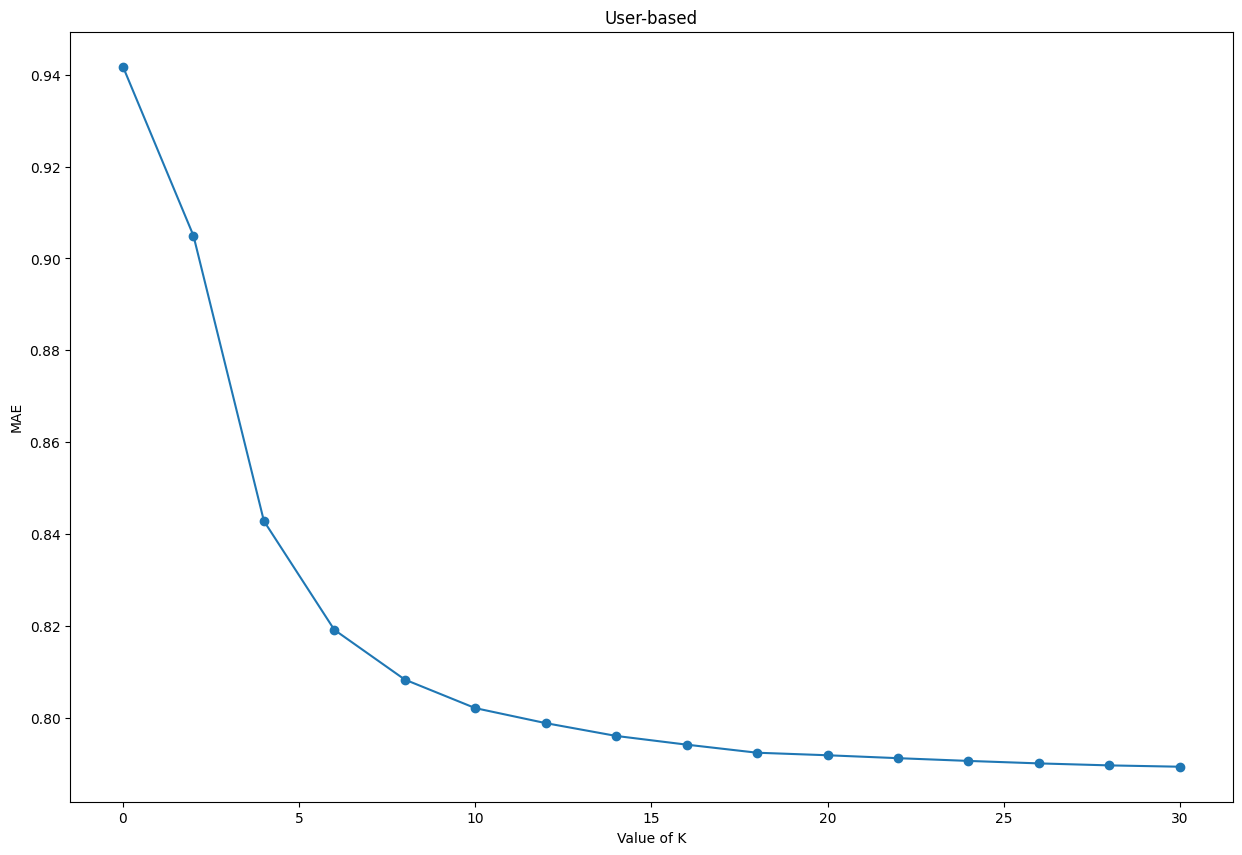

In [ ]:
# Plot the results
plt.figure(figsize=(15, 10))
plt.plot(k_values, mae_values, marker='o')
plt.xlabel('Value of K')
plt.ylabel('MAE')
plt.title('User-based')
plt.show()

### Item-based CF includes 2 steps:

- Item-based CF calculates Pearson similarity between items.
- The predicted user rating on movie is the average rating of most similar items, weighted by the similarity

#### Evaluate Item-based CF model on test set. Report MAE (mean absolute error)

In [ ]:
# Change the argument input for sim_options to build an item-based CF model
algo_item = KNNBasic(k=11, sim_options={'name': 'pearson_baseline', 'user_based': False})
algo_item.fit(trainset)

# run the trained model against the testset
test_pred = algo_item.test(testset)

# get MAE
accuracy.mae(test_pred, verbose=False)

In [ ]:
k=range(0,31,2)
best_mae = float('inf')
best_k = None
k_values=[]
mae_values=[]

for n in k:
  algo_user = KNNBasic(k=n, sim_options={'name': 'pearson_baseline', 'user_based': False})
  algo_user.fit(trainset)
  test_pred = algo_user.test(testset)

  mae_result=accuracy.mae(test_pred, verbose=False)

  k_values.append(n)
  mae_values.append(mae_result)

  if mae_result < best_mae:
      best_mae = mae_result
      best_k = n
      print(f"k={n}")
      print(f"MAE={mae_result}")
  else:
    continue

print(f"Optimal k: {best_k}")
print(f"Lowest MAE: {best_mae:.10f}")

Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
k=0
MAE=0.9417577724999999
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
k=2
MAE=0.8641802621970696
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
k=4
MAE=0.8151083342129062
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
k=6
MAE=0.8002713151654094
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
k=8
MAE=0.7907459033778499
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
k=10
MAE=0.7844787257720792
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
k=12
MAE=0.7821451

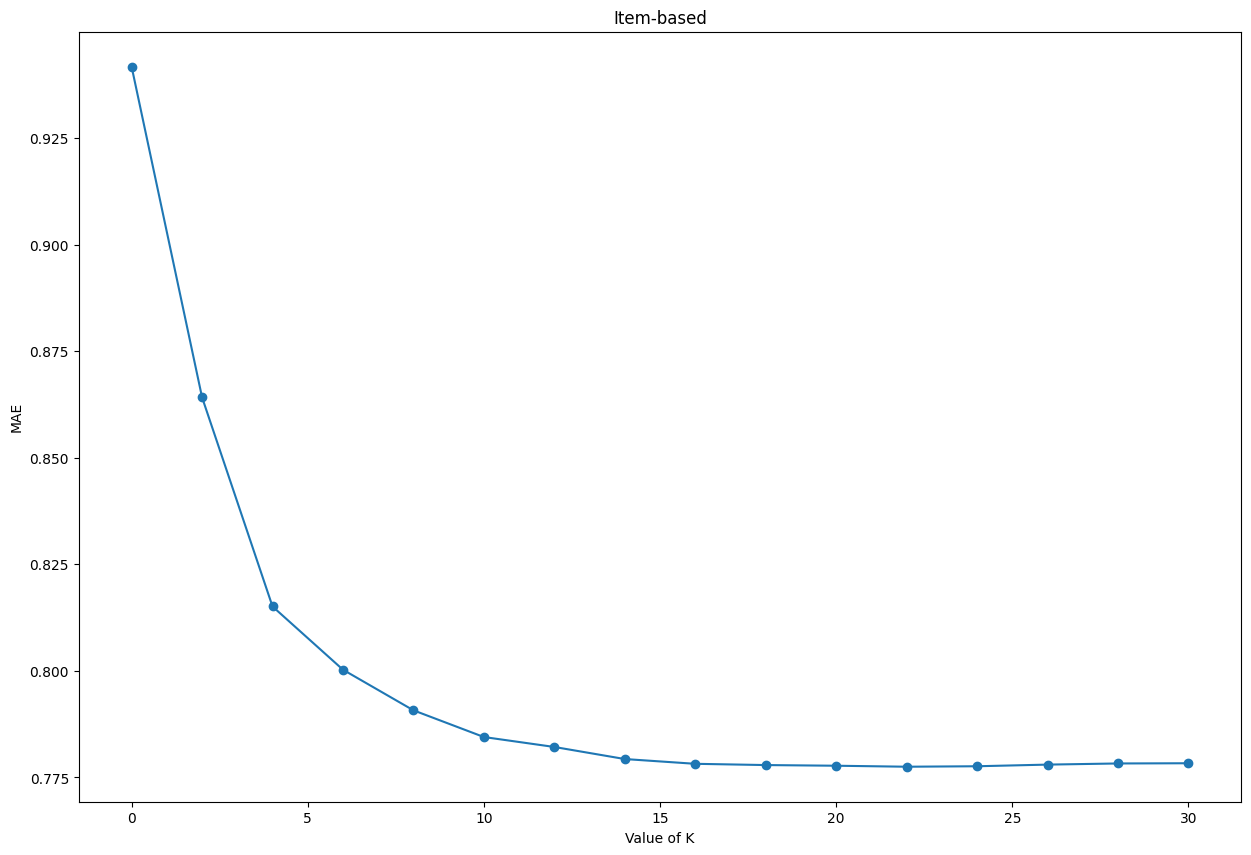

In [ ]:
x_values = k_values
y_values = mae_values

# Plot the results
plt.figure(figsize=(15, 10))
plt.plot(x_values, y_values, marker='o')
plt.xlabel('Value of K')
plt.ylabel('MAE')
plt.title('Item-based')
plt.show()

## Part 5: Combining models: Explore ensemble techniques to integrate multiple models

In [ ]:
cleaned_df=df.dropna()
cleaned_df

,user_id,movie_id,ratings,title,genres,gender,zipcode,age_desc,occ_desc
0,0,0,3,Toy Story (1995),Animation|Children's|Comedy,F,48067,Under 18,K-12 student
1,160,0,2,Toy Story (1995),Animation|Children's|Comedy,M,98107-2117,45-49,self-employed
2,537,0,5,Toy Story (1995),Animation|Children's|Comedy,M,95407,56+,self-employed
3,400,0,2,Toy Story (1995),Animation|Children's|Comedy,M,55129,18-24,other or not specified
4,84,0,2,Toy Story (1995),Animation|Children's|Comedy,M,94945,18-24,college/grad student
...,...,...,...,...,...,...,...,...,...
99995,881,77,2,"Crossing Guard, The (1995)",Drama,M,1720,18-24,artist
99996,291,97,4,Shopping (1994),Action|Thriller,M,19406,35-44,executive/managerial
99997,833,202,4,"To Wong Foo, Thanks for Everything! Julie Newm...",Comedy,F,78640,35-44,programmer
99998,392,197,5,Strange Days (1995),Action|Crime|Sci-Fi,M,55402,35-44,technician/engineer


In [ ]:
trainset


In [ ]:
algo_user = KNNBasic(k=9, sim_options={'name': 'pearson_baseline', 'user_based': True})
algo_user.fit(trainset)
algo_item = KNNBasic(k=9, sim_options={'name': 'pearson_baseline', 'user_based': False})
algo_item.fit(trainset)

# add predicted ratings by user-based and item-based cf
predictions_ub = []
predictions_ib = []

for index, row in cleaned_df.iterrows():
    usr_id = str(row['user_id'])
    mov_id = str(row['movie_id'])

    # get a prediction for specific users and items.
    pred_ub = algo_user.predict(usr_id, mov_id, r_ui=3)   # prediction by user-based cf
    pred_ib = algo_item.predict(usr_id, mov_id, r_ui=3)   # prediction by item-based cf

    predictions_ub.append(pred_ub[3])
    predictions_ib.append(pred_ib[3])

Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.
Estimating biases using als...
Computing the pearson_baseline similarity matrix...
Done computing similarity matrix.


In [ ]:
movies_df_with_cf = cleaned_df.copy()

# Below codes create and name new columns in the dataframe
movies_df_with_cf['usr_based_cf'] = predictions_ub
movies_df_with_cf['itm_based_cf'] = predictions_ib
# movies_df_with_cf

In [ ]:
# Write code here to conduct two approaches
# 1. A simple ensemble method that averages the predictions from all three models.
# 2. A feature-based approach where the predicted ratings from the user-based and item-based collaborative filtering models are used as input features for a linear regression model.


1. Ensemble Learning

In [ ]:
y_train_pred = linear_regres_fit.predict(x_train_scaled)
y_train_pred_series = pd.Series(y_train_pred, index=y_train.index, name='y_train_pred')
y_train_df = pd.concat([y_train, y_train_pred_series], axis=1)

y_test_pred = linear_regres_fit.predict(x_test_scaled)
y_test_pred_series = pd.Series(y_test_pred, index=y_test.index, name='y_test_pred')
y_test_df = pd.concat([y_test, y_test_pred_series], axis=1)

In [ ]:
train_ui_based_df = movies_df_with_cf[['usr_based_cf','itm_based_cf']]
train_ui_based_df = train_ui_based_df.loc[y_train_df.index]
train_ensemble_df = pd.concat([y_train_df, train_ui_based_df], axis=1)

test_ui_based_df = movies_df_with_cf[['usr_based_cf','itm_based_cf']]
test_ui_based_df = test_ui_based_df.loc[y_test_df.index]
test_ensemble_df = pd.concat([y_test_df, test_ui_based_df], axis=1)

In [ ]:
train_ensemble_df['ensemble_predictions'] = train_ensemble_df[['y_train_pred', 'usr_based_cf', 'itm_based_cf']].mean(axis=1)
test_ensemble_df['ensemble_predictions'] = test_ensemble_df[['y_test_pred', 'usr_based_cf', 'itm_based_cf']].mean(axis=1)

In [ ]:
from sklearn.metrics import r2_score

train_ensemble_mse = mean_squared_error(train_ensemble_df['ratings'], train_ensemble_df['ensemble_predictions'])
train_ensemble_r2 = r2_score(train_ensemble_df['ratings'], train_ensemble_df['ensemble_predictions'])
train_ensemble_mae = mean_absolute_error(train_ensemble_df['ratings'], train_ensemble_df['ensemble_predictions'])

print(f"Training Ensemble Model MSE: {train_ensemble_mse:4f}")
print(f"Training Ensemble Model R-squared: {train_ensemble_r2:4f}")
print(f"Training Ensemble Model MAE: {train_ensemble_mae:4f}")



Training Ensemble Model MSE: 1.153971
Training Ensemble Model R-squared: 0.087493
Training Ensemble Model MAE: 0.864677


In [ ]:
test_ensemble_mse = mean_squared_error(test_ensemble_df['ratings'], test_ensemble_df['ensemble_predictions'])
test_ensemble_r2 = r2_score(test_ensemble_df['ratings'], test_ensemble_df['ensemble_predictions'])
test_ensemble_mae = mean_absolute_error(test_ensemble_df['ratings'], test_ensemble_df['ensemble_predictions'])

print(f"Testing Ensemble Model MSE: {test_ensemble_mse:4f}")
print(f"Testing Ensemble Model R-squared: {test_ensemble_r2:4f}")
print(f"Testing Ensemble Model MAE: {test_ensemble_mae:4f}")



Testing Ensemble Model MSE: 1.169557
Testing Ensemble Model R-squared: 0.081060
Testing Ensemble Model MAE: 0.871948


2. Linear Regression with User-based and Item-based ratings as features

In [ ]:
# Handle missing values
movies_df_with_cf = movies_df_with_cf.dropna() # Drop value with missing title and genre
print(f"The number of rows AFTER missing value removed: {len(df_copy)}\n\n")
# df_copy.count()

# Encode categorical features
movies_df_with_cf = encoding_categorical(movies_df_with_cf)

# Create features and target list
features = movies_df_with_cf.columns.drop('ratings').tolist()
target = ['ratings']

x = movies_df_with_cf[features]
y = movies_df_with_cf[target]

# Data splitting by 80/20
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state=100)

# Standard Scaling
zscore_scaler = preprocessing.StandardScaler().fit(x_train) #Z scaler
x_train_scaled = pd.DataFrame(zscore_scaler.transform(x_train), columns = x_train.columns)# Transform X_train
x_test_scaled = pd.DataFrame(zscore_scaler.transform(x_test), columns = x_test.columns) # Use the scale of X_train to transform X_test


The number of rows AFTER missing value removed: 98883




In [ ]:
print(f"Number of Training data: {len(x_train_scaled)}")
print(f"Number of Training data: {len(x_test_scaled)}")


Number of Training data: 79106
Number of Training data: 19777


In [ ]:
# Build Linear Regression Model
linear_regres = LinearRegression()
linear_regres_fit = linear_regres.fit(x_train_scaled, y_train.values.ravel())
y_train_pred = linear_regres_fit.predict(x_train_scaled)
y_train_pred = np.clip(y_train_pred, 0, 5)

# Generate R sqr & mse score on training set
train_mse = mean_squared_error(y_train, y_train_pred)
train_r2 = linear_regres_fit.score(x_train_scaled, y_train)
train_mae = mean_absolute_error(y_train, y_train_pred)
print(f"Training MSE: {train_mse:4f}")
print(f"Training R-squared: {train_r2:4f}")
print(f"Training MAE: {train_mae:4f}\n")

# Generate MSE on test set
y_test_pred = linear_regres_fit.predict(x_test_scaled)

test_mse = mean_squared_error(y_test, y_test_pred)
test_r2 = linear_regres_fit.score(x_test_scaled, y_test)
test_mae = mean_absolute_error(y_test, y_test_pred)
print(f"Testing MSE: {test_mse:4f}")
print(f"Testing R2: {test_r2:4f}")
print(f"Testing MAE: {test_mae:4f}")


Training MSE: 0.942254
Training R-squared: 0.254794
Training MAE: 0.773565

Testing MSE: 0.952960
Testing R2: 0.251244
Testing MAE: 0.777335
